In [5]:
# Machine Learning Assignment 2
# Binary Classification using Multiple ML Algorithms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully")


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy.sparse import csr_array, issparse
/home/cloud/anaconda3/lib/python3.12/site-packages/scipy/sparse/_sputils.py:17: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  np.uintc, np.long, np.ulong, np.longlong, np.ulonglong,


AttributeError: module 'numpy' has no attribute 'long'

In [4]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 136.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 152.7 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 137.2 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [7]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

/home/cloud/anaconda3/lib/python3.12/site-packages/scipy/sparse/_sputils.py:17: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  np.uintc, np.long, np.ulong, np.longlong, np.ulonglong,


AttributeError: module 'numpy' has no attribute 'long'

In [9]:
%pip install --upgrade numpy scipy scikit-learn pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 95.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 133.1 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.1
    Uninstalling matplotlib-3.10.1:
      Successfully uninstalled matplotlib-3.10.1
Note: you may need to restart the kernel to use updated packages.


In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print("Dataset loaded successfully")
print("Number of samples:", data.data.shape[0])
print("Number of features:", data.data.shape[1])
print("Classes:", data.target_names)

df.head()

Dataset loaded successfully
Number of samples: 569
Number of features: 30
Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Dataset Information

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df["target"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nBasic Statistical Summary:")
display(df.describe())

Dataset Shape: (569, 31)

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64

Missing Values:
0

Duplicate Rows:
0

Basic Statistical Summary:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


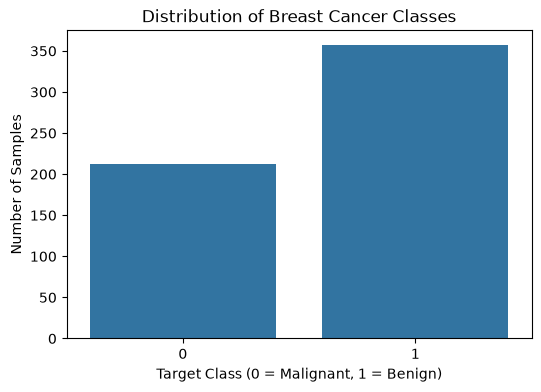

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(x="target", data=df)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Target Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")

plt.show()

In [7]:
# Step 4: Define Features (X) and Target (y)

X = df.drop("target", axis=1)
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

X shape: (569, 30)
y shape: (569,)

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [9]:
# Step 5: Split Dataset into Training and Testing Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 455
Testing samples: 114
Number of features: 30


In [11]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed successfully.
Scaled training shape: (455, 30)
Scaled testing shape: (114, 30)


In [13]:
# Step 7: Import Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

print("All machine learning models imported successfully.")

All machine learning models imported successfully.


In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

In [17]:
trained_models = {}

for name, model in models.items():

    if name in ["Logistic Regression",
                "K-Nearest Neighbors",
                "Support Vector Machine"]:

        model.fit(X_train_scaled, y_train)

    else:

        model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
K-Nearest Neighbors trained successfully.
Naive Bayes trained successfully.
Support Vector Machine trained successfully.


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [19]:
# Step 8: Evaluate all five models

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for name, model in trained_models.items():

    # Use scaled data for models that require scaling
    if name in [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Support Vector Machine"
    ]:
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Use original data for Decision Tree and Naive Bayes
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

print("All models evaluated successfully.")

All models evaluated successfully.


In [21]:
# Step 9: Model Performance Comparison

results_df = pd.DataFrame(results)

results_df = results_df.round(4)

print("MODEL PERFORMANCE COMPARISON")
display(results_df)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174
2,K-Nearest Neighbors,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [23]:
best_model = results_df.loc[results_df["F1 Score"].idxmax()]

print("Best Model based on F1 Score:")
print(best_model)

Best Model based on F1 Score:
Model        Logistic Regression
Accuracy                  0.9825
AUC                       0.9954
Precision                 0.9861
Recall                    0.9861
F1 Score                  0.9861
MCC                       0.9623
Name: 0, dtype: object


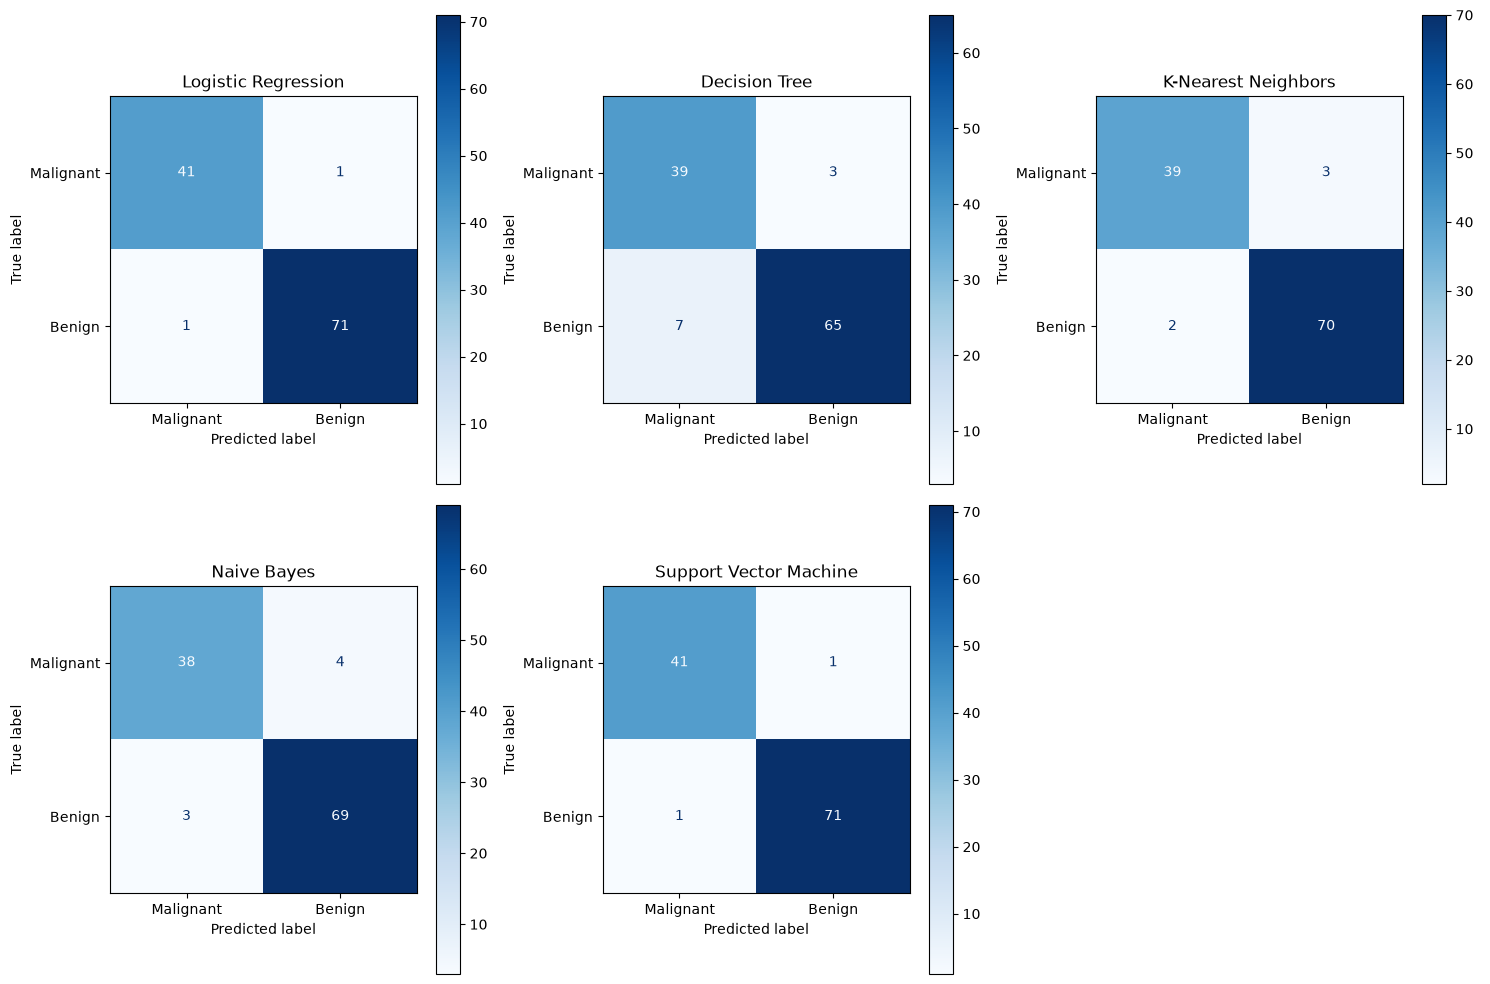

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    if name in ["Logistic Regression",
                "K-Nearest Neighbors",
                "Support Vector Machine"]:

        y_pred = model.predict(X_test_scaled)

    else:

        y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Malignant", "Benign"],
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Create Test Data CSV

test_data = X_test.copy()

test_data.to_csv("test_data.csv", index=False)

print("test_data.csv created successfully.")
print("Rows:", test_data.shape[0])
print("Columns:", test_data.shape[1])

test_data.csv created successfully.
Rows: 114
Columns: 30


In [29]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

st.set_page_config(
    page_title="Breast Cancer Classification",
    layout="wide"
)

st.title("Breast Cancer Classification using Machine Learning")

st.write(
    "This application compares five machine learning classification "
    "algorithms on the Breast Cancer Wisconsin dataset."
)

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model selection
model_name = st.selectbox(
    "Select Machine Learning Model",
    [
        "Logistic Regression",
        "Decision Tree",
        "K-Nearest Neighbors",
        "Naive Bayes",
        "Support Vector Machine"
    ]
)

if model_name == "Logistic Regression":
    model = LogisticRegression(max_iter=5000, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

elif model_name == "Decision Tree":
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

elif model_name == "K-Nearest Neighbors":
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

elif model_name == "Naive Bayes":
    model = GaussianNB()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

else:
    model = SVC(probability=True, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

st.subheader("Model Evaluation")

c1, c2, c3 = st.columns(3)

c1.metric("Accuracy", f"{accuracy:.4f}")
c2.metric("AUC", f"{auc:.4f}")
c3.metric("Precision", f"{precision:.4f}")

c4, c5, c6 = st.columns(3)

c4.metric("Recall", f"{recall:.4f}")
c5.metric("F1 Score", f"{f1:.4f}")
c6.metric("MCC", f"{mcc:.4f}")

st.subheader("Confusion Matrix")

cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Malignant", "Actual Benign"],
    columns=["Predicted Malignant", "Predicted Benign"]
)

st.dataframe(cm_df)

st.subheader("Upload Test CSV")

uploaded_file = st.file_uploader(
    "Upload test_data.csv",
    type=["csv"]
)

if uploaded_file is not None:

    uploaded_data = pd.read_csv(uploaded_file)

    st.write("Uploaded Data Preview")
    st.dataframe(uploaded_data.head())

    try:

        # Ensure feature order matches model training data
        uploaded_data = uploaded_data[X.columns]

        if model_name in [
            "Logistic Regression",
            "K-Nearest Neighbors",
            "Support Vector Machine"
        ]:
            input_data = scaler.transform(uploaded_data)
        else:
            input_data = uploaded_data

        predictions = model.predict(input_data)

        prediction_labels = np.where(
            predictions == 0,
            "Malignant",
            "Benign"
        )

        output = uploaded_data.copy()
        output["Prediction"] = prediction_labels

        st.subheader("Predictions")
        st.dataframe(output)

    except Exception as e:

        st.error(
            "Uploaded CSV must contain the same 30 feature columns "
            "as the Breast Cancer dataset."
        )

Writing app.py


In [31]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn

Writing requirements.txt
